# CSE 242 Machine Learning - Assignment 1

**Name:** Jiaxuan Wu

**Email:** jwu453@ucsc.edu  

---

## PART 1

### Q1

$$
\begin{aligned}
AB
&=
\begin{bmatrix}
3(1)+4(0) & 3(2)+4(-1) \\
2(1)+1(0) & 2(2)+1(-1)
\end{bmatrix}
=
\begin{bmatrix}
3 & 2 \\
2 & 3
\end{bmatrix},
\\[8pt]
BA
&=
\begin{bmatrix}
1(3)+2(2) & 1(4)+2(1) \\
0(3)-1(2) & 0(4)-1(1)
\end{bmatrix}
=
\begin{bmatrix}
7 & 6 \\
-2 & -1
\end{bmatrix},
\\[8pt]
(A+B)^T
&=
\begin{bmatrix}
4 & 6 \\
2 & 0
\end{bmatrix}^{T}
=
\begin{bmatrix}
4 & 2 \\
6 & 0
\end{bmatrix},
\\[8pt]
AB^T
&=
\begin{bmatrix}
3 & 4 \\
2 & 1
\end{bmatrix}
\begin{bmatrix}
1 & 0 \\
2 & -1
\end{bmatrix}
\\
&=
\begin{bmatrix}
3(1)+4(2) & 3(0)+4(-1) \\
2(1)+1(2) & 2(0)+1(-1)
\end{bmatrix}
=
\begin{bmatrix}
11 & -4 \\
4 & -1
\end{bmatrix},
\\[8pt]
\mathrm{trace}(A)
&=3+1=4,
\\[4pt]
\mathrm{trace}(AB)
&=3+3=6.
\end{aligned}
$$


In [1]:
import numpy as np
def matrix_operations(A=None, B=None):
    A = np.array([[3., 4.], [2., 1.]]) if A is None else np.array(A, dtype=float)
    B = np.array([[1., 2.], [0., -1.]]) if B is None else np.array(B, dtype=float)
    AB = A @ B
    BA = B @ A
    sum_T = (A + B).T
    ABt = A @ B.T
    return AB, BA, sum_T, ABt, float(np.trace(A)), float(np.trace(AB))
names = ['AB', 'BA', '(A+B)^T', 'AB^T', 'trace(A)', 'trace(AB)']
for name, val in zip(names, matrix_operations()):
    print(f'  {name} =\n{val}')

  AB =
[[3. 2.]
 [2. 3.]]
  BA =
[[ 7.  6.]
 [-2. -1.]]
  (A+B)^T =
[[4. 2.]
 [6. 0.]]
  AB^T =
[[11. -4.]
 [ 4. -1.]]
  trace(A) =
4.0
  trace(AB) =
6.0


### Q2

The characteristic equation is 

$$
0=\det(M - \lambda I)=(2-\lambda)^2 - 1 = \lambda^2 - 4\lambda + 3 = (\lambda - 1)(\lambda - 3)
$$

Therefore, $\lambda_1 = 1$ and $\lambda_2 = 3$.

For $\lambda_1 = 1$, we solve $(M - I)v_1 = 0$:

$$
\begin{bmatrix}
1 & -1 \\
-1 & 1
\end{bmatrix}
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
\implies x=y
\implies
v_1 =
\begin{bmatrix}
1 \\
1
\end{bmatrix}
$$

For $\lambda_2 = 3$, we solve $(M - 3I)v_2 = 0$:

$$
\begin{bmatrix}
-1 & -1 \\
-1 & -1
\end{bmatrix}
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
\implies x=-y
\implies
v_2 =
\begin{bmatrix}
1 \\
-1
\end{bmatrix}
$$

Verification:

$$
\begin{aligned}
Mv_1
&=
\begin{bmatrix}
2 & -1 \\
-1 & 2
\end{bmatrix}
\begin{bmatrix}
1 \\
1
\end{bmatrix}
=
\begin{bmatrix}
1 \\
1
\end{bmatrix}
=
1 \cdot v_1
=
\lambda_1 \cdot v_1
\\
Mv_2
&=
\begin{bmatrix}
2 & -1 \\
-1 & 2
\end{bmatrix}
\begin{bmatrix}
1 \\
-1
\end{bmatrix}
=
\begin{bmatrix}
3 \\
-3
\end{bmatrix}
=
3 \cdot v_2
=
\lambda_2 \cdot v_2
\end{aligned}
$$

In [2]:
def eigensystem(M=None):
    M = np.array([[2., -1.], [-1., 2.]]) if M is None else np.array(M, dtype=float)
    values, vectors = np.linalg.eigh(M)
    return values, vectors
vals, vecs = eigensystem()
M = np.array([[2., -1.], [-1., 2.]])
print(vals, np.allclose(M @ vecs, vecs * vals))

[1. 3.] True


### Q3

Let $A \in \mathbb{R}^{m \times n}$ and $B \in \mathbb{R}^{n \times m}$. By definition, the trace of a square matrix is the sum of its diagonal elements:

$$
\mathrm{trace}(AB)
=
\sum_{i=1}^{m} (AB)_{ii}
=
\sum_{i=1}^{m} \sum_{j=1}^{n} A_{ij}B_{ji}
$$

$$
=
\sum_{i=1}^{m} \sum_{j=1}^{n} B_{ji}A_{ij}
=
\sum_{j=1}^{n} \sum_{i=1}^{m} B_{ji}A_{ij}
=
\sum_{j=1}^{n} (BA)_{jj}
=
\mathrm{trace}(BA)
$$

### Q4

Since $\det(C) = (4)(6) - (7)(2) = 24 - 14 = 10 \neq 0$, the matrix is invertible. 

Using the formula for the inverse of a $2 \times 2$ matrix

$$
C^{-1} = \frac{1}{ad-bc}
\begin{bmatrix}
d & -b \\
-c & a
\end{bmatrix}
$$

we get:

$$
C^{-1}
=
\frac{1}{10}
\begin{bmatrix}
6 & -7 \\
-2 & 4
\end{bmatrix}
=
\begin{bmatrix}
0.6 & -0.7 \\
-0.2 & 0.4
\end{bmatrix}
$$

In [3]:
def matrix_inverse(C=None):
    C = np.array([[4., 7.], [2., 6.]]) if C is None else np.array(C, dtype=float)
    return np.linalg.solve(C, np.eye(C.shape[0]))
print(matrix_inverse())

[[ 0.6 -0.7]
 [-0.2  0.4]]


## PART 2
### Q1
(a) Since the sum of probabilities over all $k$ must equal 1, and by the exponential function, we can get

$$
1 = \sum_{k=0}^{\infty} c\frac{3^k}{k!}
= c \sum_{k=0}^{\infty} \frac{3^k}{k!}
= c \cdot e^3
\implies c = e^{-3}
$$

(b) Substituting $c = e^{-3}$, the distribution is $P(X=k) = \frac{e^{-3}3^k}{k!}$, which we recognize as a Poisson distribution with rate parameter $\lambda = 3$. For a Poisson distribution:

$$
E[X] = \lambda = 3, \quad Var(X) = \lambda = 3
$$

In [4]:
def distribution_moments(rate=3.):
    rate = float(rate)
    return float(np.exp(-rate)), rate, rate
print(distribution_moments())

(0.049787068367863944, 3.0, 3.0)


### Q2
$$
P(A \cap B) = P(A \mid B)P(B) = 0.6 \times 0.3 = 0.18
$$

$$
P(B \mid A) = \frac{P(A \cap B)}{P(A)} = \frac{0.18}{0.5} = 0.36
$$

$$
P(A \cup B) = P(A) + P(B) - P(A \cap B) = 0.5 + 0.3 - 0.18 = 0.62
$$

In [5]:
def event_probabilities(p_a=.5, p_b=.3, p_a_given_b=.6):
    p_ab = p_a_given_b * p_b
    return p_ab, p_ab / p_a, p_a + p_b - p_ab
print(event_probabilities())

(0.18, 0.36, 0.6200000000000001)


### Q3

### (a) MLE

Since the observation contains 3 heads and 2 tails, the likelihood function is

$$
L(\theta) = \theta^3(1-\theta)^2.
$$

The log-likelihood is:

$$
\ell(\theta) = 3\ln(\theta) + 2\ln(1-\theta)
$$

Differentiate and set to zero to find the maximum:

$$
\frac{d\ell}{d\theta}
=
\frac{3}{\theta}
-
\frac{2}{1-\theta}
=
0
\implies
3(1-\theta)
=
2\theta
\implies
3
=
5\theta
\implies
\theta_{MLE}
=
0.6
$$

### (b) MAP

The posterior is proportional to $L(\theta)P(\theta)$:

$$
P(\theta \mid D)
\propto
\theta^3(1-\theta)^2(2\theta)
=
2\theta^4(1-\theta)^2
$$

The log-posterior is

$$
\ell_{MAP}(\theta) = \ln(2) + 4\ln(\theta) + 2\ln(1-\theta).
$$

Differentiating:

$$
\frac{d\ell_{MAP}}{d\theta}
=
\frac{4}{\theta}
-
\frac{2}{1-\theta}
=
0
\implies
4(1-\theta)
=
2\theta
\implies
4
=
6\theta
\implies
\theta_{MAP}
=
\frac{2}{3}
$$

In [6]:
def coin_estimates(heads=3, tosses=5):
    mle = heads / tosses
    map_estimate = (heads + 1) / (tosses + 1)
    return float(mle), float(map_estimate)
print(coin_estimates())

(0.6, 0.6666666666666666)


### Q4

For $X=\{1,3,5,7\}$ ($N=4$), the log-likelihood for a Gaussian distribution is:

$$
\ell(\mu, \sigma^2)
=
-\frac{N}{2}\ln(2\pi)
-
\frac{N}{2}\ln(\sigma^2)
-
\sum_{i=1}^N \frac{(x_i-\mu)^2}{2\sigma^2}
$$

MLE for $\mu$:

$$
\frac{\partial \ell}{\partial \mu}
=
\sum_{i=1}^N \frac{x_i-\mu}{\sigma^2}
=
0
\implies
\mu_{MLE}
=
\frac{1}{N}\sum_{i=1}^N x_i
=
\frac{1+3+5+7}{4}
=
4
$$

MLE for $\sigma^2$:

$$
\frac{\partial \ell}{\partial \sigma^2}
=
-\frac{N}{2\sigma^2}
+
\sum_{i=1}^N \frac{(x_i-\mu)^2}{2(\sigma^2)^2}
=
0
\implies
\sigma^2_{MLE}
=
\frac{1}{N}\sum_{i=1}^N (x_i-\mu)^2
$$

$$
\sigma^2_{MLE}
=
\frac{(-3)^2 + (-1)^2 + 1^2 + 3^2}{4}
=
\frac{20}{4}
=
5
$$

In [7]:
def gaussian_mle(data=None):
    x = np.array([1., 3., 5., 7.]) if data is None else np.array(data, dtype=float).ravel()
    mu = x.mean()
    return float(mu), float(np.mean((x - mu) ** 2))
print(gaussian_mle())

(4.0, 5.0)


### Q5

Prior $\mu \sim \mathcal{N}(0,1)$, meaning $\mu_0 = 0$ and $\sigma_0^2 = 1$. The negative log-posterior $J(\mu)$ is:

$$
J(\mu)
=
\frac{(x-\mu)^2}{2\sigma^2}
+
\frac{(\mu-\mu_0)^2}{2\sigma_0^2}
=
\frac{(5-\mu)^2}{8}
+
\frac{\mu^2}{2}
$$

Minimize $J(\mu)$ by setting its derivative to zero:

$$
\frac{dJ}{d\mu}
=
-\frac{2(5-\mu)}{8}
+
\frac{2\mu}{2}
=
-\frac{5-\mu}{4}
+
\mu
=
0
\implies
-5+\mu+4\mu
=
0
\implies
5\mu
=
5
\implies
\mu_{MAP}
=
1
$$

In [8]:
def gaussian_map(x=5., observation_variance=4., prior_mean=0., prior_variance=1.):
    return float((prior_variance * x + observation_variance * prior_mean)
                 / (observation_variance + prior_variance))
print(gaussian_map())

1.0


### Q6

Starting from the variance definition and $\mu = E[X]$:

$$
\begin{aligned}
\operatorname{Var}(X)
&= E[(X-\mu)^2] \\
&= E[X^2 - 2\mu X + \mu^2] \\
&= E[X^2] - 2\mu E[X] + \mu^2 \\
&= E[X^2] - 2\mu^2 + \mu^2 \\
&= E[X^2] - [E[X]]^2.
\end{aligned}
$$

## PART 3

### Q1

Let $X \in \mathbb{R}^d$ have mean $\mu = E[X]$. The covariance matrix is
$$
\Sigma = E\left[(X-\mu)(X-\mu)^T\right], \qquad \Sigma_{jk} = \operatorname{Cov}(X_j, X_k).
$$

For a constant unit vector $u$ ($u^Tu=1$), $E[u^TX] = u^T E[X] = u^T\mu$, so
$$
\begin{aligned}
\operatorname{Var}(u^TX) &= E\left[(u^TX - u^T\mu)^2\right] \\
&= E\left[\left(u^T(X-\mu)\right)^2\right] \\
&= E\left[u^T(X-\mu)(X-\mu)^Tu\right] \qquad \text{(a scalar equals its transpose)} \\
&= u^T\, E\left[(X-\mu)(X-\mu)^T\right] u \qquad \text{($u$ is constant)} \\
&= u^T\Sigma u.
\end{aligned}
$$



### Q2/3/4


sample correlation: 0.6992223066425665
eigenvalues: [3.45848013 0.41070096]
components: [[-0.90667478  0.42183036]
 [-0.42183036 -0.90667478]]
explained variance ratio: [0.89385326 0.10614674]


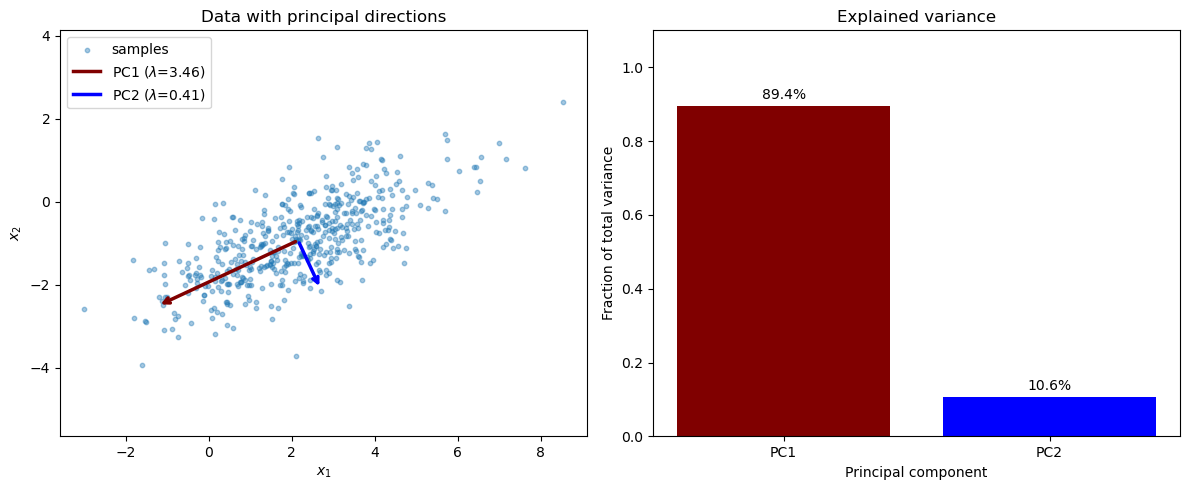

In [9]:
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    mean = np.array([2., -1.]) if mean is None else np.array(mean, dtype=float)
    covariance = (np.array([[3., 1.2], [1.2, 1.]]) if covariance is None
                  else np.array(covariance, dtype=float))
    rng = np.random.default_rng(seed)
    return rng.multivariate_normal(mean, covariance, size=n_samples)

def pca(X):
    X = np.asarray(X, dtype=float)
    mean = X.mean(axis=0) # Step 1: center
    centered = X - mean
    covariance = centered.T @ centered / (len(X) - 1) # Step 2: covariance
    eigenvalues, eigenvectors = np.linalg.eigh(covariance) # Step 3: eigendecomposition
    order = np.argsort(eigenvalues)[::-1] # Step 4: sort descending
    eigenvalues = np.clip(eigenvalues[order], 0, None)
    components = eigenvectors[:, order]
    return {
        'mean': mean,
        'centered': centered,
        'covariance': covariance,
        'eigenvalues': eigenvalues,
        'components': components,
        'scores': centered @ components,
    }

def explained_variance(eigenvalues):
    ev = np.array(eigenvalues, dtype=float)
    return ev / ev.sum()

def make_plots(X, result):
    import matplotlib.pyplot as plt
    X = np.asarray(X)
    mean, vals, vecs = result['mean'], result['eigenvalues'], result['components']
    frac = explained_variance(vals)
    colors = ['maroon', 'blue']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    # Original data + principal directions
    ax1.scatter(X[:, 0], X[:, 1], s=10, alpha=0.4, label='samples')
    for k in range(2):
        v = vecs[:, k] * 2 * np.sqrt(vals[k])
        ax1.annotate('', xy=mean + v, xytext=mean,
                     arrowprops=dict(arrowstyle='->', lw=2.5, color=colors[k]))
        ax1.plot([], [], color=colors[k], lw=2.5, label=f'PC{k+1} ($\\lambda$={vals[k]:.2f})')
    ax1.set_aspect('equal', adjustable='datalim')
    ax1.set_xlabel('$x_1$')
    ax1.set_ylabel('$x_2$')
    ax1.set_title('Data with principal directions')
    ax1.legend()
    # Explained variance
    ax2.bar(['PC1', 'PC2'], frac, color=colors)
    for i, f in enumerate(frac):
        ax2.text(i, f + 0.02, f'{f:.1%}', ha='center')
    ax2.set_ylim(0, 1.1)
    ax2.set_xlabel('Principal component')
    ax2.set_ylabel('Fraction of total variance')
    ax2.set_title('Explained variance')
    fig.tight_layout()
    return fig

X = generate_data()
result = pca(X)
print('sample correlation:', np.corrcoef(X, rowvar=False)[0, 1])
print('eigenvalues:', result['eigenvalues'])
print('components:', result['components'])
print('explained variance ratio:', explained_variance(result['eigenvalues']))
fig = make_plots(X, result)
fig.savefig('pca_figures.png', dpi=150, bbox_inches='tight')

### Q2

The data are drawn from $\mathcal{N}(\mu, \Sigma)$ with $\mu = [2, -1]^T$ and $\Sigma = \begin{bmatrix} 3 & 1.2 \\ 1.2 & 1 \end{bmatrix}$, so the true correlation is $\rho = 1.2 / \sqrt{3 \cdot 1} \approx 0.69$. The sample correlation is $\approx 0.70$, close to the true value. 
The scatter plot is an upward-tilted ellipse, which shows a positive correlation. The cloud is wider along $x_1$ because $x_1$ has the larger variance.

### Q3

1. **Center:** subtract the sample mean, $D_c = D - \bar{x}$.
2. **Covariance:** $S = \frac{1}{n-1} D_c^T D_c$. This is the sample version of $\Sigma$ in Q1.
3. **Eigendecomposition:** by Q1, the variance along a unit vector $u$ is $u^TSu$. Maximizing it subject to $u^Tu = 1$ gives $Su = \lambda u$, so the principal directions are eigenvectors of $S$, and the variance along each one is its eigenvalue $\lambda$.
4. **Sort:** order the eigenvalues from largest to smallest. PC1 is the eigenvector with the largest eigenvalue.

In the plot, PC1 points along the long axis of the ellipse and PC2 is perpendicular to it.

### Q4

The eigenvalues are $\lambda_1 = 3.46$ and $\lambda_2 = 0.41$, so PC1 explains $3.46/3.87 = 89.4\%$ of the variance and PC2 explains $10.6\%$. Most of the variance lies along PC1 because the two features are correlated.

Keeping only PC1 reduces the data from 2D to 1D while keeping about 89% of the variance. This makes the data simpler to store, compute with, and visualize, and it can remove noise. The trade-off is that the dropped components' variance is lost: fewer components give more compression but lose more information. A common rule is to keep enough components to explain about 90–95% of the variance.

# AI accreditation
ChatGPT was used to help interpret the requirements and check/polish my answers: 
https://chatgpt.com/share/6ac560ff-1538-83e8-8cb4-b6939639972a